In [2]:
import os
import time
from copy import deepcopy
from datetime import datetime
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys
# import own modules
sys.path.append(r"C:\Users\rjlea\PycharmProjects\TaskSpecificNeuralMechanismsShapeOrientationPerception")
from mytools.analysis import get_mean_data, get_oei_data
from mytools.dframe_tools import to_csv_pkl, change_dframe_colnames, index_dframe, custom_sort
from mytools.os_tools import make_paths
# import model components
from components.general_functions import join_dicts, get_condcombos
from components.general_functions import get_condcombos
from components.run import mocs_task, staircase_task, run
from components.population_code import Params, Tiling, gen_population_code

In [3]:
def set_params(cond_dicty, cardinal_idx, oblique_idx):
    # sets dictys of params for cardinal and oblique populations
    c_dicty = {}
    o_dicty = {}
    for i_param in cond_dicty:
        if not isinstance(cond_dicty[i_param], list):
            continue
        c_dicty[i_param] = cond_dicty[i_param][cardinal_idx]
        o_dicty[i_param] = cond_dicty[i_param][oblique_idx]
    return Params(c_dicty), Params(o_dicty)

In [4]:
'''
Settings
'''
# Script settings (multi processing uses high CPU - used in main script)
run_type = 'loop'  # 'single' or 'loop' or 'multi_proc' 

# Run information
run_tasks = ['con_det', 'ori_dis']  # ['con_det', 'ori_dis', 'ori_id']
run_ori_stds = [0, 45]
run_contrasts = [100]
n_level_reps = 1000
tuning_dist = 'von_mises'
decoders_ori = ['ML', 'PV', 'WTA']  # ['WTA', 'PV', 'ML']
decoders_condet = ['peak', 'sum', 'mag']  # # ['peak', 'sum', 'v_mag', 'distance', 'PV']

In [5]:
'''
Define fixed model parameters
'''
# Response defaults
fixed_params = {
    'pref_range': 45,
    'noise_type': 'poisson',
    'pref_distrib': 'cos',
    'param_distrib': 'cos',
    'crf_exponent': 2,
    'crf_c50': 24,
    'spont': 3,
}
# Orientation space
orispace = Tiling(-90, 90, step_size=0.05)


In [6]:
'''
Define orientation anisotropies so that cardinal and oblique neurons have different response parameters
'''

# To achieve this, we define the peak value for each parameter
# Let's consider a model with anisotropic orientation bandwidths
cardinal =  Params({
    'n_prefs': 3,  # Defines the number of neurons for each boundary (e.g., from -22.5 to 22.5)
    'fwhm': 57.6 * 0.5,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 3,
    'fwhm': 57.6,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace,
                            g_params={'tuning_dist': tuning_dist,
                                      'pooling_q': 6})

min_tunings = 1.3571861084064528e-05max_tunings = 1.0


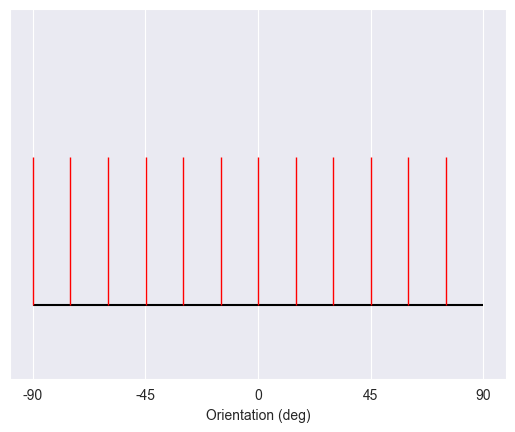

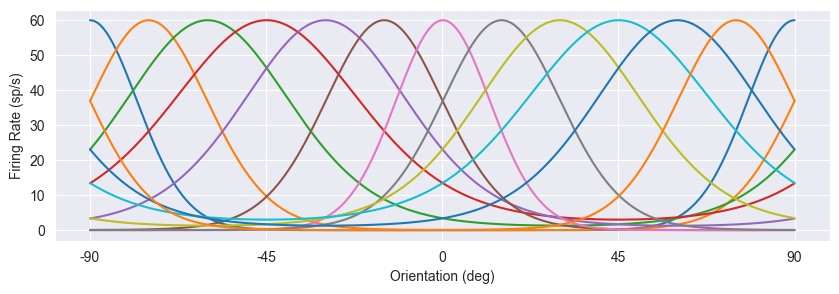

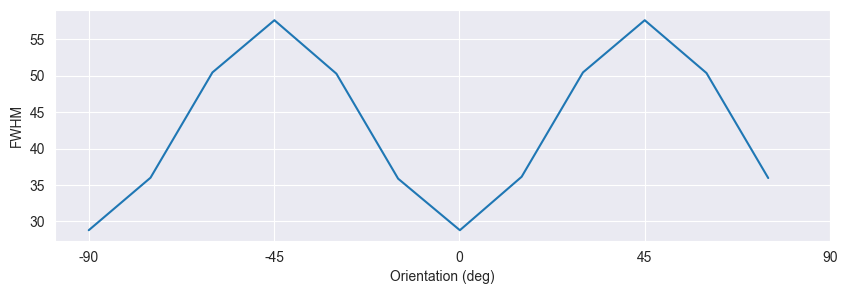

In [7]:
# Show preferences of each neuron
fig, ax = plt.subplots()
ax.hlines(0, xmin=-90, xmax=90, color='black')
ax.vlines(model.prefs, ymin=0, ymax=1, color='red', linewidth=1, zorder=5)
ax.set(xlabel='Orientation (deg)',
       ylim=(-0.5, 2), 
       yticks=[],
       xticks=[-90, -45, 0, 45, 90], xticklabels=[f"{i}" for i in [-90, -45, 0, 45, 90]],
       );

# The tuning curves of each neuron has been set up according to the defined parameters
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling, model.tunings.T)
ax.set(xlabel='Orientation (deg)', ylabel='Firing Rate (sp/s)',
       xticks=[-90, -45, 0, 45, 90], xticklabels=[f"{i}" for i in [-90, -45, 0, 45, 90]],
       );

# We can see how the anisotropic parameters vary across orientation space
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling[model.prefs_idx], model.param_distribs['fwhm'])
ax.set(xlabel='Orientation (deg)', ylabel='FWHM',
       xticks=[-90, -45, 0, 45, 90], xticklabels=[f"{i}" for i in [-90, -45, 0, 45, 90]],
       );


[Text(0.5, 0, 'Orientation Preference'), Text(0, 0.5, 'Firing Rate (sp/s)')]

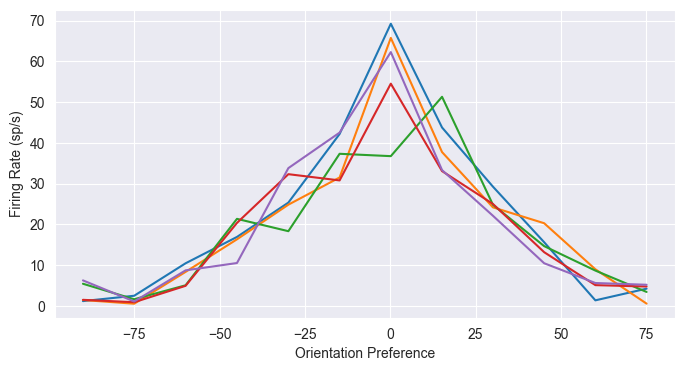

In [8]:
'''
Trial-to-trial model responses 
'''
# On each trial, noise is added to the tuned response for a given orientation
noisy_response = model.gen_stim_response(stim_ori=0, stim_contrast=100, n_reps=100)
# Plot noisy response of all neurons to that orientation for n_repeats
fig, ax = plt.subplots(figsize=(8, 4));
n_repeats = 5
plt.plot(model.prefs, noisy_response[:, :n_repeats]);
ax.set(xlabel='Orientation Preference', ylabel='Firing Rate (sp/s)')

In [ ]:
'''
Simulating model performance on contrast-detection task
'''
# Simulations uses method of constant stimuli design

# Step 0 - Define the model parameters (cardinal overrepresentation)
cardinal =  Params({
    'n_prefs': 63, 'fwhm': 57.6, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 27, 'fwhm': 57.6, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace,
                            g_params={'tuning_dist': tuning_dist,
                                      'pooling_q': 6})

# Step 1 - Define the contrast level of each simulation
levels_contrasts = np.hstack([
    np.linspace(0.01, 0.1, 3),
    np.linspace(0.1, 1, 9),
    np.linspace(1, 10, 9),
    np.linspace(10, 100, 5)]
)  # Cover a wide range of possible performance
levels_contrasts = np.asarray(list(set(levels_contrasts)))  # Remove repeated values

# Step 2 - Run simulation for each standard orientation
condet_data = run(
    task='con_det', experiment=mocs_task, model=model, decoders=decoders_condet, stdoris=[0, 45], 
    contrasts=[None], design='mocs', run_type_=run_type, n_level_reps=500, 
    _plot_psychometric=True, levels=levels_contrasts,
)

# Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)

# Todo - WHY DOES THIS SHOW AN OBLIQUE EFFECT WHEN THE BEHAVIOURAL DATA DOESNT?
fig = sns.catplot(data=condet_data, x='decoder', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar',
                  );
display(fig)


In [ ]:
'''
Simulating model performance on orientation-discrimination task
'''

# Step 0 - Define the model parameters (anisotropic bandwidths)
cardinal =  Params({
    'n_prefs': 45, 'fwhm': 57.6 * 0.5, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 45, 'fwhm': 57.6, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace, 
                            g_params={'tuning_dist': tuning_dist, 'pooling_q': 6}
                            )
# Step 1 - Define the orientation differences between standard and comparison stimuli
levels_ori_diff = np.hstack([
    np.linspace(0.01, 0.1, 3),
    np.linspace(0.1, 1, 7),
    np.linspace(1, 10, 7),
    np.linspace(10, 90, 7),
])  # Cover a wide range of possible performance
levels_ori_diff = np.asarray(list(set(levels_ori_diff)))  # Remove repeated values

# Step 2 - Run simulation for each standard orientation
oridis_data = run(
    task='ori_dis', experiment=mocs_task, model=model, decoders=decoders_ori, stdoris=[0, 45], 
    contrasts=[100], design='mocs', run_type_=run_type, n_level_reps=500, 
    _plot_psychometric=True, levels=levels_ori_diff,
)

# Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)

# Todo Compare cardinal and oblique performance
fig = sns.catplot(data=oridis_data, x='decoder', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar');
display(fig)

In [12]:
'''
Simulating spatial frequency 
    - Orientation bandwidths that decrease with increasing spatial frequency

Running multiple conditions
    - Code that loops through condition combinations to generate comprehensive simulation dataset
'''

# TODO - Different FWHM conditions to what is reported in paper

# Bandwidths corresponding to 2, 8, 16 cpd
sf_fwhm = [57.6, 30.4, 22.2]  

# Define all possible anisotropies and combinations to simulate 
conditions = {
    'n_prefs': [
        [45, 45],  # Uniform number 
        # [63, 27]  # Cardinal overrepresentation
    ],  
    'fwhm': [
        *[[i, i] for i in sf_fwhm],  # Uniformly decreasing bandwidths with increasing SF
        *[[i * 0.5, i] for i in sf_fwhm]  # Anistropic bandwidths that decrease with increasing SF
    ],
    'noise_scale': [
        [1, 1],  # Uniform noise 
        # [0.5, 1]  # Anisotropic levels of response variability
    ],
    'rmax': [
        [60, 60],  # Uniform rmax
        # [120, 60]  # Anisotropic maximum firing rates
    ]
}

# Generate a list of all simulation conditions
condition_combinations = get_condcombos(conditions)
display(condition_combinations[:5])  # Show example of condition combinations

# Loop through simulation conditions
all_data = []
for idx, cond_combo in enumerate(condition_combinations):
    print(f"Simulation {idx+1}/{len(condition_combinations)}")
    # Set cardinal and oblique parameters
    cardinal =  Params({
        **{k: v[0] for k, v in cond_combo.items()}, 
        **fixed_params
    })
    oblique = Params({
        **{k: v[1] for k, v in cond_combo.items()}, 
        **fixed_params
    })
    
    # Initialise model with these parameters
    model = gen_population_code(cardinal, oblique, orispace, g_params={'tuning_dist': tuning_dist, 'pooling_q': 6}
                                )
    
    # For this example, we'll simulate performance on the contrast detection task for one pooling method
    decoder = 'sum'
    
    # Step 1 - Define the contrast level of each simulation
    levels_contrasts = np.hstack([
        np.linspace(0.01, 0.1, 3),
        np.linspace(0.1, 1, 9),
        np.linspace(1, 10, 9),
        np.linspace(10, 100, 5)]
    )  # Cover a wide range of possible performance
    levels_contrasts = np.asarray(list(set(levels_contrasts)))  # Remove repeated values
    
    # Step 2 - Run simulation for each standard orientation
    condet_sf_data = run(
        task='con_det', experiment=mocs_task, model=model, decoders=[decoder], stdoris=[0, 45], 
        contrasts=[None], design='mocs', run_type_=run_type, n_level_reps=500, 
        _plot_psychometric=False, levels=levels_contrasts,
    )
    # Add condition information to dataset
    for k, v in cond_combo.items():
        condet_sf_data[k] = v
    
    # Number each condition
    condet_sf_data['cond_num'] = idx + 1

    # Add to full dataset
    all_data.append(condet_sf_data)
# Combine all data
all_data = pd.concat(all_data)

[{'n_prefs': [45, 45],
  'fwhm': [57.6, 57.6],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [30.4, 30.4],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [22.2, 22.2],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [28.8, 57.6],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [15.2, 30.4],
  'noise_scale': [1, 1],
  'rmax': [60, 60]}]

Simulation 1/6
min_tunings = 0.050459284734870206max_tunings = 1.0
Simulation 2/6
min_tunings = 4.1777894510715374e-05max_tunings = 1.0
Simulation 3/6
min_tunings = 7.555407826996424e-09max_tunings = 1.0
Simulation 4/6
min_tunings = 1.3571861084064528e-05max_tunings = 1.0
Simulation 5/6
min_tunings = 6.168441879772477e-18max_tunings = 1.0
Simulation 6/6
min_tunings = 6.560001872218304e-33max_tunings = 1.0


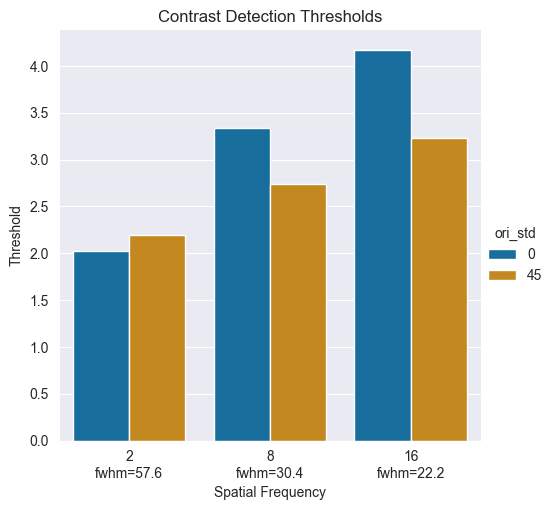

In [79]:
'''
Plot SF data
'''
# Define SF mapping: bandwidth → SF label
sf_map = {57.6: "2\nfwhm=57.6", 30.4: "8\nfwhm=30.4", 22.2: "16\nfwhm=22.2"}

# Prepare a list to collect updated DataFrames
plot_data = []

# Group by condition number
for cond_num, i_df in all_data.groupby('cond_num'):
    i_df = i_df.copy()  # Copy to avoid issues with pandas 
    
    # Isolate cardinal and oblique parameters for this simulation
    cardinal = i_df[i_df['ori_std'] == 0].iloc[0].to_dict()
    oblique = i_df[i_df['ori_std'] == 45].iloc[0].to_dict()
    
    # Apply SF labels
    sf_label = sf_map.get(oblique['fwhm'])
    if sf_label:
        i_df['sf_label'] = sf_label
    else:
        print(f"Warning: No SF label applied to condition {cond_num} (fwhm = {oblique['fwhm']})")
        
    # Create anisotropy labels to group conditions together
    i_df['proportion_cardinal'] = cardinal['n_prefs'] / i_df['n_prefs'].sum()
    i_df['bandwidth_fraction'] = cardinal['fwhm'] / oblique['fwhm']
    i_df['noise_fraction'] = cardinal['noise_scale'] / oblique['noise_scale']
    i_df['rmax_fraction'] = cardinal['rmax'] / oblique['rmax']
    
    plot_data.append(i_df)

# Concatenate all updated groups
plot_data = pd.concat(plot_data, ignore_index=True)

# Isolate a condition of interest, e.g., anisotropic bandwidths
cond_data = plot_data[plot_data['bandwidth_fraction'] == 0.5]

# Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)
fig = sns.catplot(
    data=cond_data, x='sf_label', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar', 
);
fig.ax.set(xlabel="Spatial Frequency", ylabel="Threshold", title="Contrast Detection Thresholds")
display(fig)

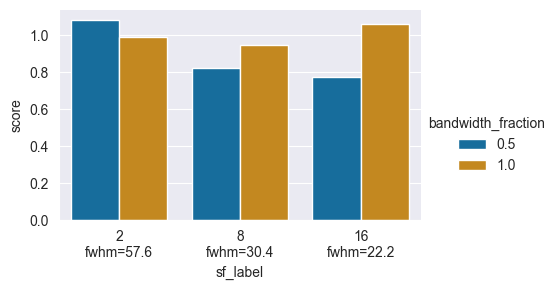

In [100]:
'''
Plotting OEI scores
'''
# Generate OEI scores for each condition combination
cond_list = ['task', 'decoder', 'proportion_cardinal', 'bandwidth_fraction', 'noise_fraction', 'rmax_fraction', 'sf_label', 'cond_num']
oei_scores = get_oei_data(plot_data, cond_list, ori_label='ori_std', dv='threshold')
oei_scores = oei_scores[["score", *cond_list]]
oei_scores = custom_sort(oei_scores, cols=['sf_label'], ordered_labels=[list(sf_map.values())])

# Plot OEI scores for various conditions
fig = sns.catplot(oei_scores, x="sf_label", y="score", hue="bandwidth_fraction",
                  dodge=4, palette='colorblind',
                  kind="bar", height=3, aspect=1.5)


''' 
In the final implementation, multiple conditions are overlaid in a single plot for comparison.
'''
